In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Funciona com o notebook aberto tanto em notebooks/ quanto na raiz do repositório.
cwd = Path.cwd().resolve()
raiz = next(
    (p for p in (cwd, *cwd.parents)
     if (p / "resultados" / "tabelas" / "e5_comparacao.csv").is_file()),
    None,
)
if raiz is None:
    raise FileNotFoundError(
        "Não encontrei resultados/tabelas/e5_comparacao.csv. "
        "Execute o notebook dentro da pasta do projeto com os arquivos já gerados."
    )

pasta_tabelas = raiz / "resultados" / "tabelas"
arquivo_e5 = pasta_tabelas / "e5_comparacao.csv"
arquivo_e1 = pasta_tabelas / "e1_frequencias.csv"
saida = raiz / "resultados" / "graficos" / "notebooks"
saida.mkdir(parents=True, exist_ok=True)

for arquivo in (arquivo_e5, arquivo_e1):
    if not arquivo.is_file():
        raise FileNotFoundError(f"CSV necessário não encontrado: {arquivo}")

print("Raiz do projeto:", raiz)
print("Gráficos serão salvos em:", saida)

Raiz do projeto: /home/joaovictor/maquina-estatistica
Gráficos serão salvos em: /home/joaovictor/maquina-estatistica/resultados/graficos/notebooks


In [2]:
df_e5 = pd.read_csv(arquivo_e5)
df_e1 = pd.read_csv(arquivo_e1)

colunas_e5 = [
    "prob_premio_teorica", "freq_premio_observada",
    "premio_medio_teorico", "premio_medio_observado",
    "lucro_medio_teorico", "lucro_medio_observado",
    "rtp_teorico", "rtp_observado",
]
percentuais = ["prob_premio_teorica", "freq_premio_observada", "rtp_teorico", "rtp_observado"]

assert {"tabela", *colunas_e5}.issubset(df_e5.columns), "Colunas faltando em e5_comparacao.csv."
assert {"lucro_x", "premio_p", "contagem", "freq_relativa"}.issubset(df_e1.columns), (
    "Colunas faltando em e1_frequencias.csv."
)

# CSV usa '%' nos percentuais; convertemos para pontos percentuais (ex.: '84.00%' -> 84.00).
for coluna in percentuais:
    df_e5[coluna] = (
        df_e5[coluna].astype(str).str.strip().str.rstrip("%")
        .str.replace(",", ".", regex=False).astype(float)
    )

for coluna in set(colunas_e5) - set(percentuais):
    df_e5[coluna] = pd.to_numeric(df_e5[coluna], errors="raise")

for coluna in ("premio_p", "contagem", "freq_relativa"):
    df_e1[coluna] = pd.to_numeric(df_e1[coluna], errors="raise")

assert set(df_e5["tabela"]) == {"Tabela Base", "Tabela +10%"}
assert len(df_e5) == 2
assert df_e5["tabela"].is_unique

comparacao = df_e5.set_index("tabela").loc[["Tabela Base", "Tabela +10%"]]
print("Comparação exportada pelo simulador:")
display(comparacao.round(4))
print("Frequências do Experimento 1, utilizadas novamente no Experimento 5:")
display(df_e1)

Comparação exportada pelo simulador:


,prob_premio_teorica,freq_premio_observada,premio_medio_teorico,premio_medio_observado,lucro_medio_teorico,lucro_medio_observado,rtp_teorico,rtp_observado
tabela,,,,,,,,
Tabela Base,4.0,4.12,0.840,0.8685,-0.160,-0.1315,84.0,86.85
Tabela +10%,4.0,4.12,0.924,0.9554,-0.076,-0.0447,92.4,95.53


Frequências do Experimento 1, utilizadas novamente no Experimento 5:


,lucro_x,premio_p,combinacao,prob_teorica,contagem,freq_relativa,diferenca_abs
0,-1,0.0,Outras (120 triplas),0.960,9588,0.9588,0.0012
1,4,5.0,A-A-A (+4),0.008,77,0.0077,0.0003
2,9,10.0,B-B-B (+9),0.008,88,0.0088,0.0008
3,14,15.0,C-C-C (+14),0.008,78,0.0078,0.0002
4,24,25.0,D-D-D (+24),0.008,88,0.0088,0.0008
5,49,50.0,E-E-E (+49),0.008,81,0.0081,0.0001


In [3]:
aposta = 1.0
quantidade_rodadas = int(df_e1["contagem"].sum())
assert quantidade_rodadas == 10_000, "E1 deve totalizar 10.000 rodadas."
assert len(df_e1) == 6, "E1 precisa conter as seis categorias de lucro."
assert (df_e1["contagem"] >= 0).all()
assert np.isclose(df_e1["freq_relativa"].sum(), 1.0, atol=1e-8)
assert np.allclose(
    df_e1["contagem"] / quantidade_rodadas,
    df_e1["freq_relativa"],
    atol=1e-8,
)

# Uma categoria com prêmio zero e cinco com prêmio positivo.
premios_basicos = df_e1["premio_p"].to_numpy(dtype=float)
contagens = df_e1["contagem"].to_numpy(dtype=float)
assert np.array_equal(np.sort(premios_basicos), [0, 5, 10, 15, 25, 50])
assert df_e1.loc[df_e1["premio_p"] == 0, "contagem"].shape[0] == 1

premios_teoricos_base = np.array([5., 10., 15., 25., 50.])
probabilidade_premio_teorica = 5 / 125
probabilidade_premio_observada = contagens[premios_basicos > 0].sum() / quantidade_rodadas

indicadores = {}
for nome, fator in [("Tabela Base", 1.0), ("Tabela +10%", 1.10)]:
    # Valores teóricos derivados da tabela e das 125 triplas equiprováveis.
    premio_teorico = (premios_teoricos_base * fator).sum() / 125
    lucro_teorico = premio_teorico - aposta
    rtp_teorico = 100 * premio_teorico / aposta

    # Valores observados derivados das mesmas contagens do E1.
    premios_cenario = premios_basicos * fator
    premio_observado = np.dot(premios_cenario, contagens) / quantidade_rodadas
    lucro_observado = premio_observado - aposta
    rtp_observado = 100 * premio_observado / aposta

    indicadores[nome] = {
        "Prob. teórica de prêmio (%)": 100 * probabilidade_premio_teorica,
        "Freq. observada de prêmio (%)": 100 * probabilidade_premio_observada,
        "Prêmio médio teórico": premio_teorico,
        "Prêmio médio observado": premio_observado,
        "Lucro médio teórico": lucro_teorico,
        "Lucro médio observado": lucro_observado,
        "RTP teórico (%)": rtp_teorico,
        "RTP observado (%)": rtp_observado,
    }

    exportado = comparacao.loc[nome]
    verificacoes = [
        ("prob_premio_teorica", 100 * probabilidade_premio_teorica, 0.011),
        ("freq_premio_observada", 100 * probabilidade_premio_observada, 0.011),
        ("premio_medio_teorico", premio_teorico, 0.00011),
        ("premio_medio_observado", premio_observado, 0.00011),
        ("lucro_medio_teorico", lucro_teorico, 0.00011),
        ("lucro_medio_observado", lucro_observado, 0.00011),
        ("rtp_teorico", rtp_teorico, 0.011),
        ("rtp_observado", rtp_observado, 0.011),
    ]
    for coluna, valor_recalculado, tolerancia in verificacoes:
        assert abs(exportado[coluna] - valor_recalculado) < tolerancia, (
            f"Divergência em {nome} / {coluna}: "
            f"CSV={exportado[coluna]} vs recálculo={valor_recalculado}"
        )

tabela_indicadores = pd.DataFrame.from_dict(indicadores, orient="index")
assert np.isclose(tabela_indicadores.loc["Tabela Base", "Lucro médio teórico"], -0.16)
assert np.isclose(tabela_indicadores.loc["Tabela +10%", "Lucro médio teórico"], -0.076)
assert np.isclose(tabela_indicadores.loc["Tabela Base", "RTP teórico (%)"], 84.0)
assert np.isclose(tabela_indicadores.loc["Tabela +10%", "RTP teórico (%)"], 92.4)
assert np.isclose(
    tabela_indicadores.loc["Tabela Base", "Freq. observada de prêmio (%)"],
    tabela_indicadores.loc["Tabela +10%", "Freq. observada de prêmio (%)"],
)

print("Conferências concluídas: 10.000 rodadas reutilizadas e indicadores consistentes.")
print("Valores abaixo são calculados sem o arredondamento prévio do CSV do E5:")
display(tabela_indicadores.round(4))

Conferências concluídas: 10.000 rodadas reutilizadas e indicadores consistentes.
Valores abaixo são calculados sem o arredondamento prévio do CSV do E5:


,Prob. teórica de prêmio (%),Freq. observada de prêmio (%),Prêmio médio teórico,Prêmio médio observado,Lucro médio teórico,Lucro médio observado,RTP teórico (%),RTP observado (%)
Tabela Base,4.0,4.12,0.840,0.8685,-0.160,-0.1315,84.0,86.850
Tabela +10%,4.0,4.12,0.924,0.9554,-0.076,-0.0446,92.4,95.535


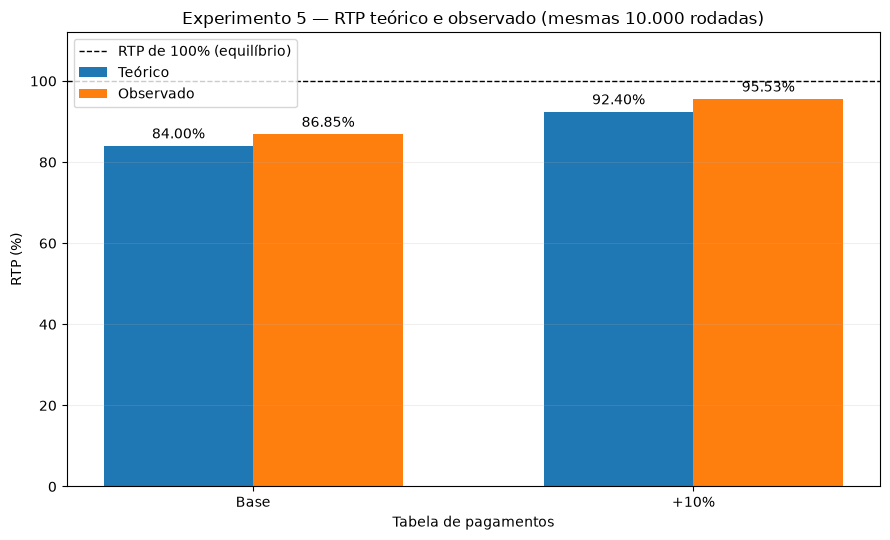

Gráfico salvo em: /home/joaovictor/maquina-estatistica/resultados/graficos/notebooks/e5_rtp_teorico_vs_observado.png


In [4]:
nomes = ["Base", "+10%"]
indices = np.arange(2)
largura = 0.34
rtp_teoria = tabela_indicadores["RTP teórico (%)"].to_numpy()
rtp_observado = tabela_indicadores["RTP observado (%)"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 5.5))
b1 = ax.bar(indices - largura/2, rtp_teoria, largura, label="Teórico")
b2 = ax.bar(indices + largura/2, rtp_observado, largura, label="Observado")
ax.axhline(100, linestyle="--", linewidth=1, color="black", label="RTP de 100% (equilíbrio)")
ax.bar_label(b1, fmt="%.2f%%", padding=3)
ax.bar_label(b2, fmt="%.2f%%", padding=3)
ax.set_xticks(indices, nomes)
ax.set_ylim(0, 112)
ax.set_ylabel("RTP (%)")
ax.set_xlabel("Tabela de pagamentos")
ax.set_title("Experimento 5 — RTP teórico e observado (mesmas 10.000 rodadas)")
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()

arquivo_rtp = saida / "e5_rtp_teorico_vs_observado.png"
fig.savefig(arquivo_rtp, dpi=200, bbox_inches="tight")
plt.show()
print("Gráfico salvo em:", arquivo_rtp)

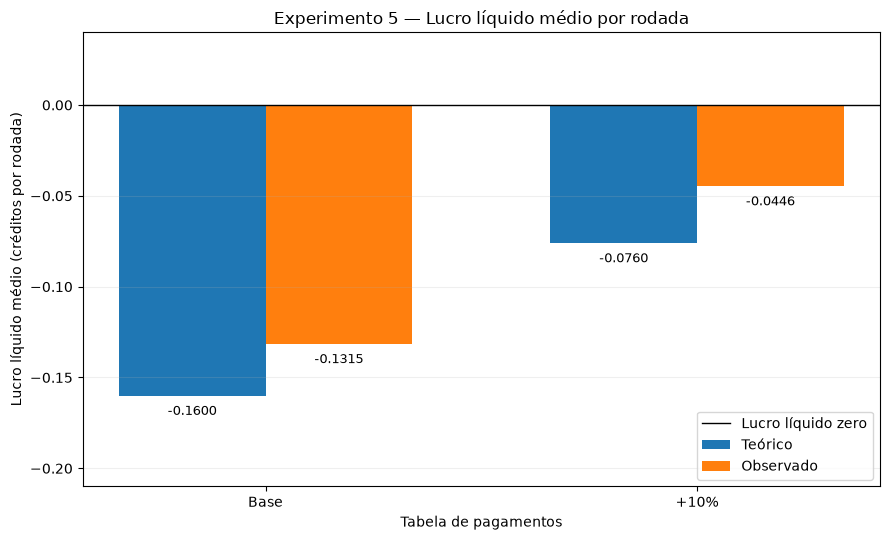

Gráfico salvo em: /home/joaovictor/maquina-estatistica/resultados/graficos/notebooks/e5_lucro_medio_teorico_vs_observado.png


In [5]:
lucro_teoria = tabela_indicadores["Lucro médio teórico"].to_numpy()
lucro_observado = tabela_indicadores["Lucro médio observado"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 5.5))
b1 = ax.bar(indices - largura/2, lucro_teoria, largura, label="Teórico")
b2 = ax.bar(indices + largura/2, lucro_observado, largura, label="Observado")
ax.axhline(0, color="black", linewidth=1, label="Lucro líquido zero")

for barra in [*b1, *b2]:
    altura = barra.get_height()
    ax.annotate(
        f"{altura:.4f}",
        (barra.get_x() + barra.get_width()/2, altura),
        xytext=(0, -7 if altura < 0 else 4),
        textcoords="offset points",
        va="top" if altura < 0 else "bottom",
        ha="center",
        fontsize=9,
    )

ax.set_xticks(indices, nomes)
ax.set_xlabel("Tabela de pagamentos")
ax.set_ylabel("Lucro líquido médio (créditos por rodada)")
ax.set_title("Experimento 5 — Lucro líquido médio por rodada")
ax.set_ylim(min(-0.21, float(np.min([*lucro_teoria, *lucro_observado])) - 0.03), 0.04)
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()

arquivo_lucro = saida / "e5_lucro_medio_teorico_vs_observado.png"
fig.savefig(arquivo_lucro, dpi=200, bbox_inches="tight")
plt.show()
print("Gráfico salvo em:", arquivo_lucro)

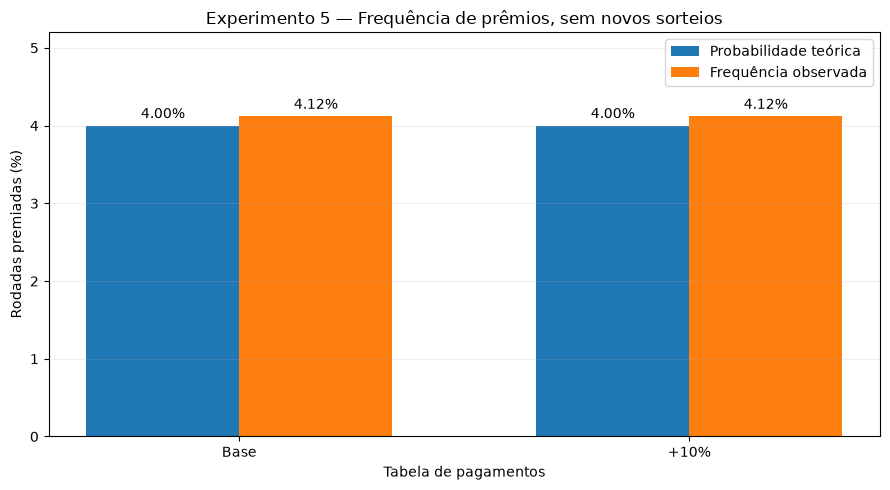

Gráfico salvo em: /home/joaovictor/maquina-estatistica/resultados/graficos/notebooks/e5_frequencia_premios.png


In [6]:
freq_teorica = tabela_indicadores["Prob. teórica de prêmio (%)"].to_numpy()
freq_observada = tabela_indicadores["Freq. observada de prêmio (%)"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(indices - largura/2, freq_teorica, largura, label="Probabilidade teórica")
b2 = ax.bar(indices + largura/2, freq_observada, largura, label="Frequência observada")
ax.bar_label(b1, fmt="%.2f%%", padding=3)
ax.bar_label(b2, fmt="%.2f%%", padding=3)
ax.set_xticks(indices, nomes)
ax.set_ylim(0, 5.2)
ax.set_ylabel("Rodadas premiadas (%)")
ax.set_xlabel("Tabela de pagamentos")
ax.set_title("Experimento 5 — Frequência de prêmios, sem novos sorteios")
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()

arquivo_frequencia = saida / "e5_frequencia_premios.png"
fig.savefig(arquivo_frequencia, dpi=200, bbox_inches="tight")
plt.show()
print("Gráfico salvo em:", arquivo_frequencia)

In [7]:
base = tabela_indicadores.loc["Tabela Base"]
aumentada = tabela_indicadores.loc["Tabela +10%"]

print("EXPERIMENTO 5 — SÍNTESE (mesmas 10.000 rodadas da semente 2026)")
print(f"Probabilidade teórica de prêmio: {base['Prob. teórica de prêmio (%)']:.2f}% em ambas as tabelas")
print(f"Frequência observada: {base['Freq. observada de prêmio (%)']:.2f}% em ambas as tabelas")
print()
print(f"RTP teórico: {base['RTP teórico (%)']:.2f}% → {aumentada['RTP teórico (%)']:.2f}%")
print(f"Diferença de RTP teórico: {aumentada['RTP teórico (%)'] - base['RTP teórico (%)']:+.2f} p.p.")
print(f"RTP observado: {base['RTP observado (%)']:.3f}% → {aumentada['RTP observado (%)']:.3f}%")
print(f"Lucro teórico por rodada: {base['Lucro médio teórico']:.3f} → {aumentada['Lucro médio teórico']:.3f} crédito")
print(f"Lucro observado por rodada: {base['Lucro médio observado']:.5f} → {aumentada['Lucro médio observado']:.5f} crédito")
print()
print("Arquivos gerados pelo notebook:")
for arq in (arquivo_rtp, arquivo_lucro, arquivo_frequencia):
    print(" -", arq.relative_to(raiz))

EXPERIMENTO 5 — SÍNTESE (mesmas 10.000 rodadas da semente 2026)
Probabilidade teórica de prêmio: 4.00% em ambas as tabelas
Frequência observada: 4.12% em ambas as tabelas

RTP teórico: 84.00% → 92.40%
Diferença de RTP teórico: +8.40 p.p.
RTP observado: 86.850% → 95.535%
Lucro teórico por rodada: -0.160 → -0.076 crédito
Lucro observado por rodada: -0.13150 → -0.04465 crédito

Arquivos gerados pelo notebook:
 - resultados/graficos/notebooks/e5_rtp_teorico_vs_observado.png
 - resultados/graficos/notebooks/e5_lucro_medio_teorico_vs_observado.png
 - resultados/graficos/notebooks/e5_frequencia_premios.png
